# Kết quả và kiểm chứng: DSCMR và CLIP4CMR trên Pascal Sentence

Notebook này **chạy được ngay sau khi clone repo**, không cần GPU, dữ liệu hay trọng số:

1. Tính lại mAP@ALL từ embedding test đã lưu của các mô hình cuối (6 cấu hình × 5 seed) và đối chiếu với số đã báo cáo.
2. Vẽ lại các hình kết quả (lưu vào `assets/`).
3. Bảng ablation cải tiến A và B của CLIP4CMR.
4. Ví dụ truy hồi ảnh → văn bản và văn bản → ảnh của mô hình tốt nhất.

Cách chạy (từ thư mục gốc của repo):

```bash
pip install -r requirements.txt jupyter
jupyter notebook notebooks/results_and_verification.ipynb
```

Trọng số của mọi mô hình nằm ở GitHub Releases (`weights-v1`), xem README.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'common').exists():          # notebook được mở từ thư mục notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from common.metrics import label_relevance, map_all, recall_at_k

V3 = ROOT / 'reports/improve_v3_20261030'
ASSETS = ROOT / 'assets'
ASSETS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Thư mục repo:', ROOT.name)

Thư mục repo: SEG


## 1. Tính lại mAP từ embedding test

Mỗi lượt chạy lưu embedding đã chuẩn hóa L2 của 200 ảnh và 200 văn bản test (`test_features.npz`). Hai mẫu được coi là liên quan khi cùng lớp. Điểm tương đồng là cosine; với vector đã chuẩn hóa, thứ tự xếp hạng trùng với khoảng cách Euclid mà mã huấn luyện dùng.

In [2]:
CONFIGS = {  # tên hiển thị: (thư mục, mô hình)
    'CLIP4CMR gốc (RN50)':            ('confirm/base_rn50_c4',          'CLIP4CMR'),
    'CLIP4CMR + DFN5B (đóng băng)':   ('confirm/frozen_dfn5b_c4AB',     'CLIP4CMR'),
    'CLIP4CMR + fine-tune 2 block':   ('finetune/confirm/c4_AB_L2',     'CLIP4CMR'),
    'DSCMR gốc (RN50)':               ('confirm/base_rn50_ds',          'DSCMR'),
    'DSCMR + ensemble 3 encoder':     ('confirm/ens3_ds_capmean',       'DSCMR'),
    'DSCMR + fine-tune 4 block':      ('finetune/confirm/ds_L4',        'DSCMR'),
}
SEEDS = (42, 43, 44, 45, 46)

def evaluate(npz):
    t = np.load(npz)
    s = t['image'] @ t['text'].T
    rel = label_relevance(t['label'], t['label'])
    return {'I2T': map_all(s, rel)['mAP@ALL'], 'T2I': map_all(s.T, rel.T)['mAP@ALL'],
            'I2T R@1': recall_at_k(s, rel)['R@1'], 'T2I R@1': recall_at_k(s.T, rel.T)['R@1']}

# số đã lưu lúc chạy thí nghiệm
stored = {(r['config'], r['seed']): (r['I2T'], r['T2I'])
          for r in json.loads((V3 / 'confirm_results.json').read_text())}
for cfg in ('c4_AB_L2', 'ds_L4'):
    for r in json.loads((V3 / f'finetune/confirm/{cfg}/test_results.json').read_text()):
        stored[(cfg, r['seed'])] = tuple(r['none'])

results, worst = {}, 0.0
for name, (folder, _) in CONFIGS.items():
    runs = [evaluate(V3 / folder / f'seed{s}' / 'test_features.npz') for s in SEEDS]
    results[name] = runs
    key = folder.split('/')[-1]
    for s, r in zip(SEEDS, runs):
        worst = max(worst, abs(r['I2T'] - stored[(key, s)][0]), abs(r['T2I'] - stored[(key, s)][1]))

print(f'Sai lệch lớn nhất so với số đã báo cáo: {worst:.2e}')
assert worst < 1e-9

print(f"\n{'Cấu hình':32s} {'I2T':>14s} {'T2I':>14s} {'TB':>7s}")
for name, runs in results.items():
    i2t = np.array([r['I2T'] for r in runs]) * 100
    t2i = np.array([r['T2I'] for r in runs]) * 100
    print(f'{name:32s} {i2t.mean():6.2f} ± {i2t.std(ddof=1):4.2f} {t2i.mean():6.2f} ± {t2i.std(ddof=1):4.2f} '
          f'{(i2t.mean() + t2i.mean()) / 2:7.2f}')

Sai lệch lớn nhất so với số đã báo cáo: 0.00e+00

Cấu hình                                    I2T            T2I      TB
CLIP4CMR gốc (RN50)               68.48 ± 0.70  67.87 ± 0.45   68.17
CLIP4CMR + DFN5B (đóng băng)      73.71 ± 0.18  73.53 ± 0.22   73.62
CLIP4CMR + fine-tune 2 block      76.63 ± 0.43  75.68 ± 0.51   76.15
DSCMR gốc (RN50)                  68.86 ± 0.53  69.89 ± 0.31   69.38
DSCMR + ensemble 3 encoder        73.75 ± 0.37  74.38 ± 0.53   74.06
DSCMR + fine-tune 4 block         74.78 ± 0.57  72.70 ± 0.69   73.74


## 2. Hình kết quả

Cột là trung bình 5 seed, thanh sai số là độ lệch chuẩn giữa các seed. Đường đứt nét là trung bình hai chiều của số công bố trong bài báo CLIP4CMR gốc (69.8 / 69.2).

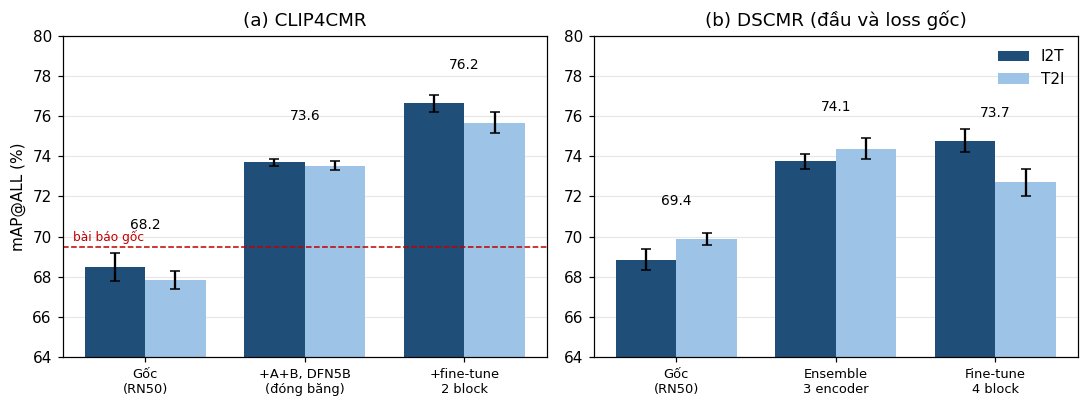

In [3]:
def bar_panel(ax, names, title, labels):
    x = np.arange(len(names)); w = 0.38
    for k, (d, color) in enumerate((('I2T', '#1F4E79'), ('T2I', '#9DC3E6'))):
        m = [np.mean([r[d] for r in results[n]]) * 100 for n in names]
        e = [np.std([r[d] for r in results[n]], ddof=1) * 100 for n in names]
        ax.bar(x + (k - .5) * w, m, w, yerr=e, capsize=3, color=color, label=d)
    for i, n in enumerate(names):
        avg = np.mean([(r['I2T'] + r['T2I']) / 2 for r in results[n]]) * 100
        ax.text(i, avg + 2.2, f'{avg:.1f}', ha='center', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8.5)
    ax.set_ylim(64, 80); ax.set_title(title); ax.grid(axis='y', alpha=.3); ax.set_axisbelow(True)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={'width_ratios': [1, 1]})
c4 = list(CONFIGS)[:3]; ds = list(CONFIGS)[3:]
bar_panel(axes[0], c4, '(a) CLIP4CMR', ['Gốc\n(RN50)', '+A+B, DFN5B\n(đóng băng)', '+fine-tune\n2 block'])
bar_panel(axes[1], ds, '(b) DSCMR (đầu và loss gốc)', ['Gốc\n(RN50)', 'Ensemble\n3 encoder', 'Fine-tune\n4 block'])
axes[0].axhline(69.5, ls='--', color='#C00000', lw=1); axes[0].text(-.45, 69.8, 'bài báo gốc', color='#C00000', fontsize=8)
axes[0].set_ylabel('mAP@ALL (%)'); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(ASSETS / 'fig_results.png', dpi=160); plt.show()

### Mức tăng theo từng seed

So sánh theo cặp: mỗi seed của mô hình cải tiến so với **cùng seed** của mô hình gốc. Mọi điểm nằm trên 0 nghĩa là cải tiến tăng ở mọi seed, không phụ thuộc may mắn.

CLIP4CMR I2T: tăng TB +8.15 điểm, tăng ở 5/5 seed
CLIP4CMR T2I: tăng TB +7.81 điểm, tăng ở 5/5 seed
DSCMR I2T: tăng TB +5.93 điểm, tăng ở 5/5 seed
DSCMR T2I: tăng TB +2.81 điểm, tăng ở 5/5 seed


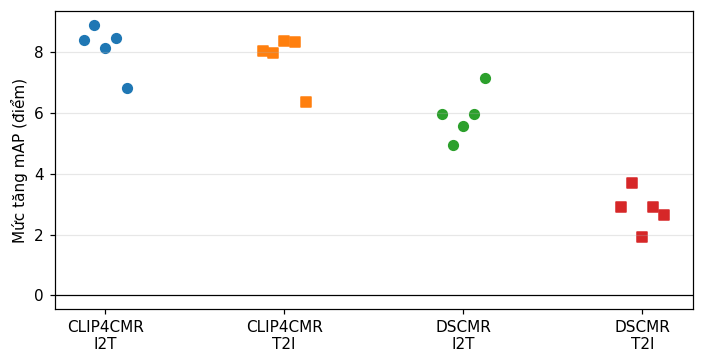

In [4]:
pairs = {'CLIP4CMR': ('CLIP4CMR gốc (RN50)', 'CLIP4CMR + fine-tune 2 block'),
         'DSCMR': ('DSCMR gốc (RN50)', 'DSCMR + fine-tune 4 block')}
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for k, (model, (base, best)) in enumerate(pairs.items()):
    for j, (d, mk) in enumerate((('I2T', 'o'), ('T2I', 's'))):
        g = [(results[best][i][d] - results[base][i][d]) * 100 for i in range(len(SEEDS))]
        xs = np.full(len(g), k * 2 + j) + np.linspace(-.12, .12, len(g))
        ax.scatter(xs, g, marker=mk, s=40, label=f'{model} {d}')
        print(f'{model} {d}: tăng TB {np.mean(g):+.2f} điểm, tăng ở {sum(x > 0 for x in g)}/{len(g)} seed')
ax.axhline(0, color='k', lw=.8)
ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(['CLIP4CMR\nI2T', 'CLIP4CMR\nT2I', 'DSCMR\nI2T', 'DSCMR\nT2I'])
ax.set_ylabel('Mức tăng mAP (điểm)'); ax.grid(axis='y', alpha=.3)
fig.tight_layout(); fig.savefig(ASSETS / 'fig_paired_gains.png', dpi=160); plt.show()

## 3. Ablation cải tiến A và B (CLIP4CMR, split tác giả)

Đọc từ `reports/clip4cmr_author_split_20261030/results.csv`. **A_res** là đối chứng: cùng adapter nhưng prototype ngẫu nhiên. A_res không tăng, A_sem tăng ở mọi seed, nên lợi ích đến từ ngữ nghĩa của prototype.

In [5]:
import csv
rows = list(csv.DictReader(open(ROOT / 'reports/clip4cmr_author_split_20261030/results.csv', encoding='utf-8-sig')))
base = {(r['backbone'], r['seed'], r['direction']): float(r['mAP@ALL']) for r in rows if r['variant'] == 'base'}
print(f"{'Backbone':9s} {'Cấu hình':10s} {'I2T':>7s} {'T2I':>7s} {'Tăng TB':>8s}")
for bb in ('rn50', 'vitl14'):
    for v in ('base', 'B', 'A_res', 'A_sem', 'A_sem+B'):
        sel = [r for r in rows if r['backbone'] == bb and r['variant'] == v]
        m = {d: np.mean([float(r['mAP@ALL']) for r in sel if r['direction'] == d]) * 100 for d in ('I2T', 'T2I')}
        gain = np.mean([float(r['mAP@ALL']) - base[(bb, r['seed'], r['direction'])] for r in sel]) * 100
        print(f"{bb:9s} {v:10s} {m['I2T']:7.2f} {m['T2I']:7.2f} {gain:+8.2f}")

Backbone  Cấu hình       I2T     T2I  Tăng TB
rn50      base         68.48   67.87    +0.00
rn50      B            69.22   68.38    +0.63
rn50      A_res        68.44   68.38    +0.23
rn50      A_sem        70.35   69.92    +1.96
rn50      A_sem+B      70.90   70.61    +2.58
vitl14    base         72.14   71.68    +0.00
vitl14    B            72.53   72.85    +0.78
vitl14    A_res        68.90   69.32    -2.80
vitl14    A_sem        72.42   71.93    +0.26
vitl14    A_sem+B      72.62   71.80    +0.30


### AP theo từng lớp của mô hình tốt nhất

AP trung bình của các truy vấn thuộc mỗi lớp (CLIP4CMR + fine-tune 2 block, seed 42, chiều ảnh → văn bản).

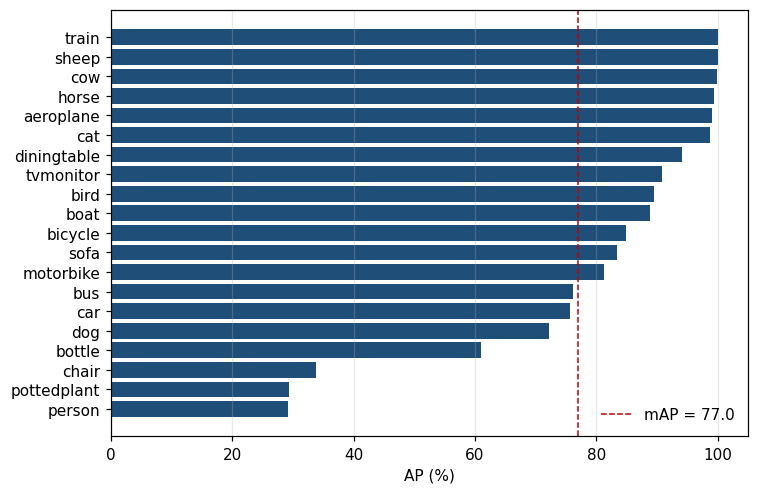

In [6]:
meta = json.loads((V3 / 'test_ids.json').read_text())
classes = meta['class_names']
t = np.load(V3 / 'finetune/confirm/c4_AB_L2/seed42/test_features.npz')
s = t['image'] @ t['text'].T
rel = label_relevance(t['label'], t['label'])
order = np.argsort(-s, axis=1, kind='stable')
ranked = np.take_along_axis(rel, order, axis=1)
prec = np.cumsum(ranked, axis=1) / np.arange(1, s.shape[1] + 1)
ap = (prec * ranked).sum(1) / ranked.sum(1)
per_class = [ap[t['label'] == c].mean() * 100 for c in range(len(classes))]
idx = np.argsort(per_class)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh([classes[i] for i in idx], [per_class[i] for i in idx], color='#1F4E79')
ax.axvline(ap.mean() * 100, ls='--', color='#C00000', lw=1, label=f'mAP = {ap.mean()*100:.1f}')
ax.set_xlabel('AP (%)'); ax.legend(frameon=False, loc='lower right'); ax.grid(axis='x', alpha=.3)
fig.tight_layout(); fig.savefig(ASSETS / 'fig_per_class_ap.png', dpi=160); plt.show()

## 4. Ví dụ truy hồi

Dùng embedding của mô hình tốt nhất (CLIP4CMR + fine-tune 2 block, seed 42). Câu mô tả lấy từ `reports/clip4cmr_investigation_20261014/pascal_raw_manifest.json` (Pascal Sentence, giấy phép Creative Commons). Ảnh không đưa vào repo; link trỏ tới trang gốc của UIUC.

In [7]:
manifest = {r['id']: r for r in json.loads(
    (ROOT / 'reports/clip4cmr_investigation_20261014/pascal_raw_manifest.json').read_text(encoding='utf-8'))}
ids = meta['ids']

def show_i2t(q, k=5):
    r = manifest[ids[q]]
    print(f"Ảnh truy vấn: {ids[q]} [{classes[t['label'][q]]}]  {r['image_url']}")
    for rank, j in enumerate(np.argsort(-s[q], kind='stable')[:k], 1):
        ok = 'đúng' if t['label'][j] == t['label'][q] else 'SAI '
        print(f"  {rank}. ({ok}) [{classes[t['label'][j]]}] {manifest[ids[j]]['captions'][0]}")

def show_t2i(q, k=5):
    print(f"Câu truy vấn [{classes[t['label'][q]]}]: {manifest[ids[q]]['captions'][0]}")
    for rank, j in enumerate(np.argsort(-s[:, q], kind='stable')[:k], 1):
        ok = 'đúng' if t['label'][j] == t['label'][q] else 'SAI '
        print(f"  {rank}. ({ok}) ảnh {ids[j]} [{classes[t['label'][j]]}]")

rng = np.random.default_rng(0)
for q in rng.choice(len(ids), 2, replace=False):
    show_i2t(int(q)); print()
show_t2i(int(rng.integers(len(ids))))

Ảnh truy vấn: 2008_004969 [boat]  https://vision.cs.uiuc.edu/pascal-sentences/boat/2008_004969.jpg
  1. (đúng) [boat] A boat with four sails is sailing on water.
  2. (đúng) [boat] A male and female in a moving sail boat on a lake
  3. (đúng) [boat] A boat is docked in water.
  4. (đúng) [boat] An empty boat begs to be used.
  5. (đúng) [boat] a view over a cliff with a big sailboat in the distance

Ảnh truy vấn: 2008_000043 [diningtable]  https://vision.cs.uiuc.edu/pascal-sentences/diningtable/2008_000043.jpg
  1. (đúng) [diningtable] A wooden table sits in the green dining room on a shiny wooden floor.
  2. (đúng) [diningtable] A black and wood colored dining room set in a small apartment.
  3. (đúng) [diningtable] A country dinner setting with a bounty of food such as, steak, fruit, salad and coffee.
  4. (đúng) [diningtable] A dining room is in a house with brown carpet, a table and a fan.
  5. (đúng) [diningtable] A kitchen with pine doors and a table and chairs.

Câu truy vấn [di

## Ghi chú

- Embedding test được sinh bởi các lượt chạy trong `reports/improve_v3_20261030/` (mã ở tag `experiments-2026-10-31`).
- Để huấn luyện lại hoặc nạp trọng số, xem README mục 5 và GitHub Releases `weights-v1`.